# [GSE115727](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE115727)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-01-27
> - Modified: 2025-02-15

# 1. Experimental Design

> The RNA exosome contributes to gene expression regulation during stem cell differentiation.
> - Marta Lloret-Llinares, Evdoxia Karadoulama, Yun Chen, Luke A Wojenski, Geno J Villafano, Jette Bornholdt, Robin Andersson, Leighton Core, Albin Sandelin, Torben Heick Jensen, The RNA exosome contributes to gene expression regulation during stem cell differentiation, Nucleic Acids Research, Volume 46, Issue 21, 30 November 2018, Pages 11502–11513, https://doi.org/10.1093/nar/gky817.
> - polyA RNA-seq
> - Illumina HiSeq 4000, PE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Status | Replicate |
| - | - | - | - | - | - | - | - |
| ESC Control | Mus musculus | mESC | Embryionic stem cell | E14TG2a | Control | Undifferentiated | rep1~3 |
| EB Control | Mus musculus | mESC | mESC-derived EB      | E14TG2a | Control | Differentiated at 3 day | rep1~3 |
| ESC shRBM7  | Mus musculus | mESC | Embryionic stem cell | E14TG2a | shRBM7 | Undifferentiated        | rep1~3 |
| EB shRBM7 | Mus musculus | mESC | mESC-derived EB | E14TG2a | shRBM7 | Differentiated at 3 day | rep1~3 |
| ESC shRRP40 | Mus musculus | mESC | Embryionic stem cell | E14TG2a | shRRP40 | Undifferentiated | rep1~3 |
| EB shRRP40 | Mus musculus | mESC | mESC-derived EB | E14TG2a | shRRP40 | Differentiated at 3 day | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Rbm7_GSE115727/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 55335    26

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Genotype", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("ESC", "EB")),
        Genotype = factor(Genotype, levels = c("Control", "shRBM7", "shRRP40")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Genotype, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Genotype,Replicate
,<fct>,<fct>,<fct>
ESC_Control_rep1,ESC,Control,rep1
ESC_Control_rep2,ESC,Control,rep2
ESC_Control_rep3,ESC,Control,rep3
ESC_shRBM7_rep1,ESC,shRBM7,rep1
ESC_shRBM7_rep2,ESC,shRBM7,rep2
ESC_shRBM7_rep3,ESC,shRBM7,rep3
ESC_shRRP40_rep1,ESC,shRRP40,rep1
ESC_shRRP40_rep2,ESC,shRRP40,rep2
ESC_shRRP40_rep3,ESC,shRRP40,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Genotype)

class: DESeqDataSet 
dim: 55335 18 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Genotype", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("ESC", "EB")),
        Genotype = factor(Genotype, levels = c("Control", "shRBM7", "shRRP40")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Genotype, Replicate) |>
    select("sampleName", "fileName", "Cell", "Genotype", "Replicate") |>
    as.data.frame()

head(coldata)

,sampleName,fileName,Cell,Genotype,Replicate
,<chr>,<chr>,<fct>,<fct>,<fct>
1,ESC_Control_rep1,ESC_Control_rep1.tsv,ESC,Control,rep1
2,ESC_Control_rep2,ESC_Control_rep2.tsv,ESC,Control,rep2
3,ESC_Control_rep3,ESC_Control_rep3.tsv,ESC,Control,rep3
4,ESC_shRBM7_rep1,ESC_shRBM7_rep1.tsv,ESC,shRBM7,rep1
5,ESC_shRBM7_rep2,ESC_shRBM7_rep2.tsv,ESC,shRBM7,rep2
6,ESC_shRBM7_rep3,ESC_shRBM7_rep3.tsv,ESC,shRBM7,rep3


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Genotype,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 18 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Genotype", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("ESC", "EB")),
        Genotype = factor(Genotype, levels = c("Control", "shRBM7", "shRRP40")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Genotype, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

head(coldata)

,Cell,Genotype,Replicate
,<fct>,<fct>,<fct>
ESC_Control_rep1,ESC,Control,rep1
ESC_Control_rep2,ESC,Control,rep2
ESC_Control_rep3,ESC,Control,rep3
ESC_shRBM7_rep1,ESC,shRBM7,rep1
ESC_shRBM7_rep2,ESC,shRBM7,rep2
ESC_shRBM7_rep3,ESC,shRBM7,rep3


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Genotype)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 18 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Genotype", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("ESC", "EB")),
        Genotype = factor(Genotype, levels = c("Control", "shRBM7", "shRRP40")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Genotype, Replicate) |>
    select("names", "files", "Cell", "Genotype", "Replicate") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files")) |> head()

,names,Cell,Genotype,Replicate
,<chr>,<fct>,<fct>,<fct>
1,ESC_Control_rep1,ESC,Control,rep1
2,ESC_Control_rep2,ESC,Control,rep2
3,ESC_Control_rep3,ESC,Control,rep3
4,ESC_shRBM7_rep1,ESC,shRBM7,rep1
5,ESC_shRBM7_rep2,ESC,shRBM7,rep2
6,ESC_shRBM7_rep3,ESC,shRBM7,rep3


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-11 06:24:36

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtai

In [20]:
DESeqDataSet(gse, design = ~ Genotype)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 18 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(4): names Cell Genotype Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Genotype", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("ESC", "EB")),
        Genotype = factor(Genotype, levels = c("Control", "shRBM7", "shRRP40")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Genotype, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata |> head()

,Cell,Genotype,Replicate
,<fct>,<fct>,<fct>
ESC_Control_rep1,ESC,Control,rep1
ESC_Control_rep2,ESC,Control,rep2
ESC_Control_rep3,ESC,Control,rep3
ESC_shRBM7_rep1,ESC,shRBM7,rep1
ESC_shRBM7_rep2,ESC,shRBM7,rep2
ESC_shRBM7_rep3,ESC,shRBM7,rep3


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Genotype)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 18 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 18 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Genotype)

dds

class: DESeqDataSet 
dim: 55335 18 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(18): ESC_Control_rep1 ESC_Control_rep2 ... EB_shRRP40_rep2
  EB_shRRP40_rep3
colData names(3): Cell Genotype Replicate

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Genotype)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 19970 
 Remove: 35365 
 Retention rate: 36.09 %


In [29]:
design <- model.matrix(~ group + Cell, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18947 
 Remove: 36388 
 Retention rate: 34.24 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.07273337,0.13284030,0,0.03775806,0.0707367,0.03702272,0.1428348,9.2484731,5.4935025,7.5149941,5.7330014,4.6803906,6.0576340,6.5199116,6.2754984,6.8748410
ENSMUSG00000103377.1,0.08046084,0,0.00000000,0.00000000,0,0.11327418,0.0000000,0.00000000,0.0000000,1.2980313,0.6604211,1.2581664,0.5548066,0.7873554,1.0444197,0.8489468,0.7445507,1.0855012
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.06642015,0,0.00000000,0.0000000,0.03702272,0.0357087,0.6490157,0.3902488,0.7140945,0.4808324,0.4811616,0.6266518,0.6112417,0.4254575,1.0131345
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.03321007,0,0.00000000,0.0000000,0.00000000,0.0000000,0.6490157,0.4803062,0.3060405,0.4438453,0.6123876,0.3829539,0.5093681,0.3190931,0.7960342
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.00000000,0.0000000,0.00000000,0.0000000,1.0546504,0.7204593,0.8501125,0.2219226,0.6561295,0.5222098,0.3395787,0.6381863,0.5065672
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.03321007,0,0.00000000,0.0000000,0.00000000,0.0000000,1.6225391,1.4108995,1.0541394,1.7383940,1.9246466,1.3229316,1.9016409,1.7372849,1.7368019


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.01193524,0.02179854,0,0.00619594,0.0116076,0.006075274,0.02343860,1.5176359,0.9014609,1.2331792,0.9407616,0.7680326,0.9940325,1.0698903,1.0297831,1.1281327
ENSMUSG00000103377.1,0.02854233,0,0.00000000,0.00000000,0,0.04018240,0.0000000,0.000000000,0.00000000,0.4604581,0.2342749,0.4463166,0.1968097,0.2793031,0.3704930,0.3011518,0.2641187,0.3850661
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.02974480,0,0.00000000,0.0000000,0.016579811,0.01599136,0.2906474,0.1747644,0.3197915,0.2153302,0.2154777,0.2806322,0.2737312,0.1905318,0.4537100
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.01438288,0,0.00000000,0.0000000,0.000000000,0.00000000,0.2810808,0.2080148,0.1325424,0.1922240,0.2652176,0.1658527,0.2206012,0.1381954,0.3447528
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.00000000,0.0000000,0.000000000,0.00000000,0.5127129,0.3502476,0.4132778,0.1078866,0.3189740,0.2538696,0.1650845,0.3102510,0.2462651
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.01102592,0,0.00000000,0.0000000,0.000000000,0.00000000,0.5386916,0.4684261,0.3499799,0.5771560,0.6389929,0.4392203,0.6313549,0.5767878,0.5766275


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.03428058,0.06945579,0,0.01808775,0.03564046,0.01681955,0.06704771,4.2877729,2.5637066,3.0631688,2.6076747,2.1101896,2.6039531,3.0763688,2.6703637,3.0487497
ENSMUSG00000103377.1,0.08717615,0,0.00000000,0.00000000,0,0.11730410,0.00000000,0.00000000,0.00000000,1.3009311,0.6662654,1.1086329,0.5455322,0.7673926,0.9705380,0.8659335,0.6848947,1.0406311
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.09477465,0,0.00000000,0.00000000,0.04590163,0.04574437,0.8211654,0.4970205,0.7943496,0.5968687,0.5920305,0.7351402,0.7870882,0.4940741,1.2261396
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.04582758,0,0.00000000,0.00000000,0.00000000,0.00000000,0.7941370,0.5915831,0.3292302,0.5328212,0.7286924,0.4344653,0.6343179,0.3583589,0.9316856
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.00000000,0.00000000,0.00000000,0.00000000,1.4485665,0.9960855,1.0265659,0.2990482,0.8763894,0.6650332,0.4746848,0.8045218,0.6655250
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.03513144,0,0.00000000,0.00000000,0.00000000,0.00000000,1.5219641,1.3321789,0.8693363,1.5998050,1.7556497,1.1505752,1.8154015,1.4956870,1.5583209


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.000000,0,2.069012,3.386696,0,1.011928,1.946045,1.02974,3.9312757,251.21410,143.00447,214.971241,150.580346,124.17991,161.40151,174.345429,169.137594,181.56389
ENSMUSG00000103377.1,2.343226,0,0.000000,0.000000,0,3.035784,0.000000,0.00000,0.0000000,35.25812,17.19179,35.990660,14.572292,20.89008,27.82785,22.701228,20.067172,28.66798
ENSMUSG00000104017.1,0.000000,0,0.000000,1.693348,0,0.000000,0.000000,1.02974,0.9828189,17.62906,10.15879,20.427132,12.629319,12.76616,16.69671,16.344884,11.466956,26.75678
ENSMUSG00000103025.1,0.000000,0,0.000000,0.846674,0,0.000000,0.000000,0.00000,0.0000000,17.62906,12.50312,8.754485,11.657833,16.24784,10.20354,13.620737,8.600217,21.02319
ENSMUSG00000103201.1,0.000000,0,0.000000,0.000000,0,0.000000,0.000000,0.00000,0.0000000,28.64722,18.75468,24.318014,5.828917,17.40840,13.91392,9.080491,17.200433,13.37839
ENSMUSG00000103161.1,0.000000,0,0.000000,0.846674,0,0.000000,0.000000,0.00000,0.0000000,44.07265,36.72792,30.154337,45.659847,51.06464,35.24861,50.850750,46.823402,45.86877


,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.01242579,0.02033936,0,0.006077301,0.01168729,0.006184273,0.02360992,1.5087077,0.8588369,1.2910452,0.9043351,0.7457829,0.9693233,1.0470602,1.0157837,1.0904118
ENSMUSG00000103377.1,0.03042164,0,0.00000000,0.00000000,0,0.039412987,0.00000000,0.000000000,0.00000000,0.4577492,0.2231977,0.4672596,0.1891892,0.2712118,0.3612834,0.2947256,0.2605281,0.3721908
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.02775371,0,0.000000000,0.00000000,0.016877278,0.01610825,0.2889375,0.1665009,0.3347975,0.2069926,0.2092354,0.2736564,0.2678901,0.1879416,0.4385395
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.01342010,0,0.000000000,0.00000000,0.000000000,0.00000000,0.2794272,0.1981792,0.1387619,0.1847811,0.2575344,0.1617300,0.2158938,0.1363167,0.3332254
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.000000000,0.00000000,0.000000000,0.00000000,0.5096966,0.3336868,0.4326706,0.1037092,0.3097334,0.2475591,0.1615618,0.3060333,0.2380308
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.01028785,0,0.000000000,0.00000000,0.000000000,0.00000000,0.5355225,0.4462775,0.3664024,0.5548084,0.6204815,0.4283024,0.6178825,0.5689466,0.5573470


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.07664233,0.12794443,0,0.03772674,0.07296703,0.03851239,0.1465632,9.1338483,5.2434369,7.8371438,5.5245447,4.5353324,5.9538250,6.3127394,6.2853705,6.7219667
ENSMUSG00000103377.1,0.08699223,0,0.00000000,0.00000000,0,0.11318023,0.00000000,0.00000000,0.0000000,1.2819436,0.6303585,1.3121010,0.5346334,0.7629531,1.0265215,0.8219713,0.7457219,1.0613632
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.06397222,0,0.00000000,0.00000000,0.03851239,0.0366408,0.6409718,0.3724846,0.7447060,0.4633489,0.4662491,0.6159129,0.5918193,0.4261268,0.9906056
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.03198611,0,0.00000000,0.00000000,0.00000000,0.0000000,0.6409718,0.4584426,0.3191597,0.4277067,0.5934080,0.3763912,0.4931828,0.3195951,0.7783330
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.00000000,0.00000000,0.00000000,0.0000000,1.0415792,0.6876639,0.8865547,0.2138533,0.6357943,0.5132608,0.3287885,0.6391902,0.4953028
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.03198611,0,0.00000000,0.00000000,0.00000000,0.0000000,1.6024295,1.3466751,1.0993279,1.6751845,1.8649965,1.3002606,1.8412157,1.7400178,1.6981811


,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,0.00000000,0,0.01257669,0.02099515,0,0.006190801,0.01197359,0.006319722,0.02405041,1.4988264,0.8604261,1.2860426,0.9065548,0.7442291,0.9769979,1.0358942,1.0314031,1.1030467
ENSMUSG00000103377.1,0.03085925,0,0.00000000,0.00000000,0,0.040149071,0.00000000,0.000000000,0.00000000,0.4547512,0.2236107,0.4654491,0.1896536,0.2706467,0.3641439,0.2915826,0.2645342,0.3765034
ENSMUSG00000104017.1,0.00000000,0,0.00000000,0.02864855,0,0.000000000,0.00000000,0.017246927,0.01640878,0.2870451,0.1668090,0.3335002,0.2075006,0.2087994,0.2758231,0.2650333,0.1908315,0.4436210
ENSMUSG00000103025.1,0.00000000,0,0.00000000,0.01385280,0,0.000000000,0.00000000,0.000000000,0.00000000,0.2775971,0.1985459,0.1382242,0.1852346,0.2569978,0.1630105,0.2135915,0.1384128,0.3370866
ENSMUSG00000103201.1,0.00000000,0,0.00000000,0.00000000,0,0.000000000,0.00000000,0.000000000,0.00000000,0.5063584,0.3343043,0.4309940,0.1039637,0.3090881,0.2495191,0.1598388,0.3107390,0.2407889
ENSMUSG00000103161.1,0.00000000,0,0.00000000,0.01061956,0,0.000000000,0.00000000,0.000000000,0.00000000,0.5320151,0.4471033,0.3649827,0.5561702,0.6191887,0.4316934,0.6112934,0.5776952,0.5638051


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,-5.522970,-5.748676,-3.383787,-2.796486,-5.586647,-4.143306,-3.454683,-4.113571,-2.600480,3.19438311,2.3944491,2.9735882,2.4705019,2.1879341,2.5779565,2.6620183,2.6560674,2.75267492
ENSMUSG00000103377.1,-3.201042,-5.748676,-5.705715,-5.966411,-5.586647,-2.920914,-5.776612,-5.698534,-5.770405,0.38070057,-0.6333340,0.4112440,-0.8560726,-0.3508054,0.0616106,-0.2542710,-0.3893431,0.10976507
ENSMUSG00000104017.1,-5.522970,-5.748676,-5.705715,-3.644483,-5.586647,-5.728269,-5.776612,-4.113571,-4.185443,-0.59727313,-1.3702996,-0.3913099,-1.0553814,-1.0366968,-0.6596734,-0.7172430,-1.1717516,0.01191775
ENSMUSG00000103025.1,-5.522970,-5.748676,-5.705715,-4.381448,-5.586647,-5.728269,-5.776612,-5.698534,-5.770405,-0.59727313,-1.0807930,-1.5696471,-1.1664127,-0.7022778,-1.3455648,-0.9725000,-1.5676803,-0.32911917
ENSMUSG00000103201.1,-5.522970,-5.748676,-5.705715,-5.966411,-5.586647,-5.728269,-5.776612,-5.698534,-5.770405,0.08625321,-0.5104773,-0.1451493,-2.1098292,-0.6060624,-0.9149304,-1.5343789,-0.6061544,-0.96299127
ENSMUSG00000103161.1,-5.522970,-5.748676,-5.705715,-4.381448,-5.586647,-5.728269,-5.776612,-5.698534,-5.770405,0.69818276,0.4446685,0.1597053,0.7595867,0.9154747,0.3976598,0.8934826,0.8137488,0.77894058


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,3.694073,3.641541,3.837399,3.902030,3.678093,3.741853,3.813021,3.748130,3.969421,7.045497,6.466023,6.883015,6.515004,6.317446,6.586597,6.666192,6.634143,6.707273
ENSMUSG00000103377.1,2.896799,2.735611,2.738569,2.724636,2.744268,2.930879,2.734114,2.738227,2.734831,3.945214,3.516892,3.962711,3.429826,3.616623,3.794472,3.670228,3.598115,3.812696
ENSMUSG00000104017.1,2.403717,2.395987,2.397802,2.493485,2.401313,2.396805,2.395071,2.460431,2.456043,3.120812,2.885074,3.198764,2.970106,2.971788,3.097857,3.087969,2.930431,3.346737
ENSMUSG00000103025.1,2.186170,2.179777,2.181276,2.226898,2.184180,2.180452,2.179019,2.181103,2.179382,2.892109,2.743667,2.606129,2.711743,2.851965,2.661046,2.777744,2.600318,2.983893
ENSMUSG00000103201.1,2.323120,2.314602,2.316606,2.307186,2.320476,2.315505,2.313589,2.316375,2.314074,3.354080,3.116773,3.257966,2.644454,3.068378,2.964154,2.786999,3.067099,2.945583
ENSMUSG00000103161.1,3.050128,3.028737,3.033814,3.080690,3.043539,3.031029,3.026158,3.033229,3.027393,4.532127,4.402501,4.255819,4.563141,4.646382,4.368535,4.650015,4.583281,4.567141


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,ESC_Control_rep1,ESC_Control_rep2,ESC_Control_rep3,ESC_shRBM7_rep1,ESC_shRBM7_rep2,ESC_shRBM7_rep3,ESC_shRRP40_rep1,ESC_shRRP40_rep2,ESC_shRRP40_rep3,EB_Control_rep1,EB_Control_rep2,EB_Control_rep3,EB_shRBM7_rep1,EB_shRBM7_rep2,EB_shRBM7_rep3,EB_shRRP40_rep1,EB_shRRP40_rep2,EB_shRRP40_rep3
ENSMUSG00000051951.5,3.679282,3.679282,4.255237,4.413126,3.679282,4.083433,4.238077,4.086951,4.468598,8.109786,7.389283,7.906341,7.453398,7.216239,7.540255,7.637660,7.599264,7.689231
ENSMUSG00000103377.1,4.291687,3.679282,3.679282,3.679282,3.679282,4.374827,3.679282,3.679282,3.679282,5.859289,5.268915,5.878287,5.153051,5.414980,5.649004,5.480487,5.384000,5.674583
ENSMUSG00000104017.1,3.679282,3.679282,3.679282,4.200954,3.679282,3.679282,3.679282,4.086951,4.077615,5.287162,4.924946,5.397650,5.058590,5.065518,5.247901,5.232730,4.997842,5.615625
ENSMUSG00000103025.1,3.679282,3.679282,3.679282,4.049159,3.679282,3.679282,3.679282,3.679282,3.679282,5.287162,5.052160,4.840318,5.008061,5.228510,4.927528,5.107809,4.830558,5.419917
ENSMUSG00000103201.1,3.679282,3.679282,3.679282,3.679282,3.679282,3.679282,3.679282,3.679282,3.679282,5.673957,5.332861,5.536138,4.634871,5.277989,5.121948,4.860625,5.269278,5.095983
ENSMUSG00000103161.1,3.679282,3.679282,3.679282,4.049159,3.679282,3.679282,3.679282,3.679282,3.679282,6.071546,5.897134,5.718616,6.106419,6.218834,5.859040,6.214558,6.131422,6.110943


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


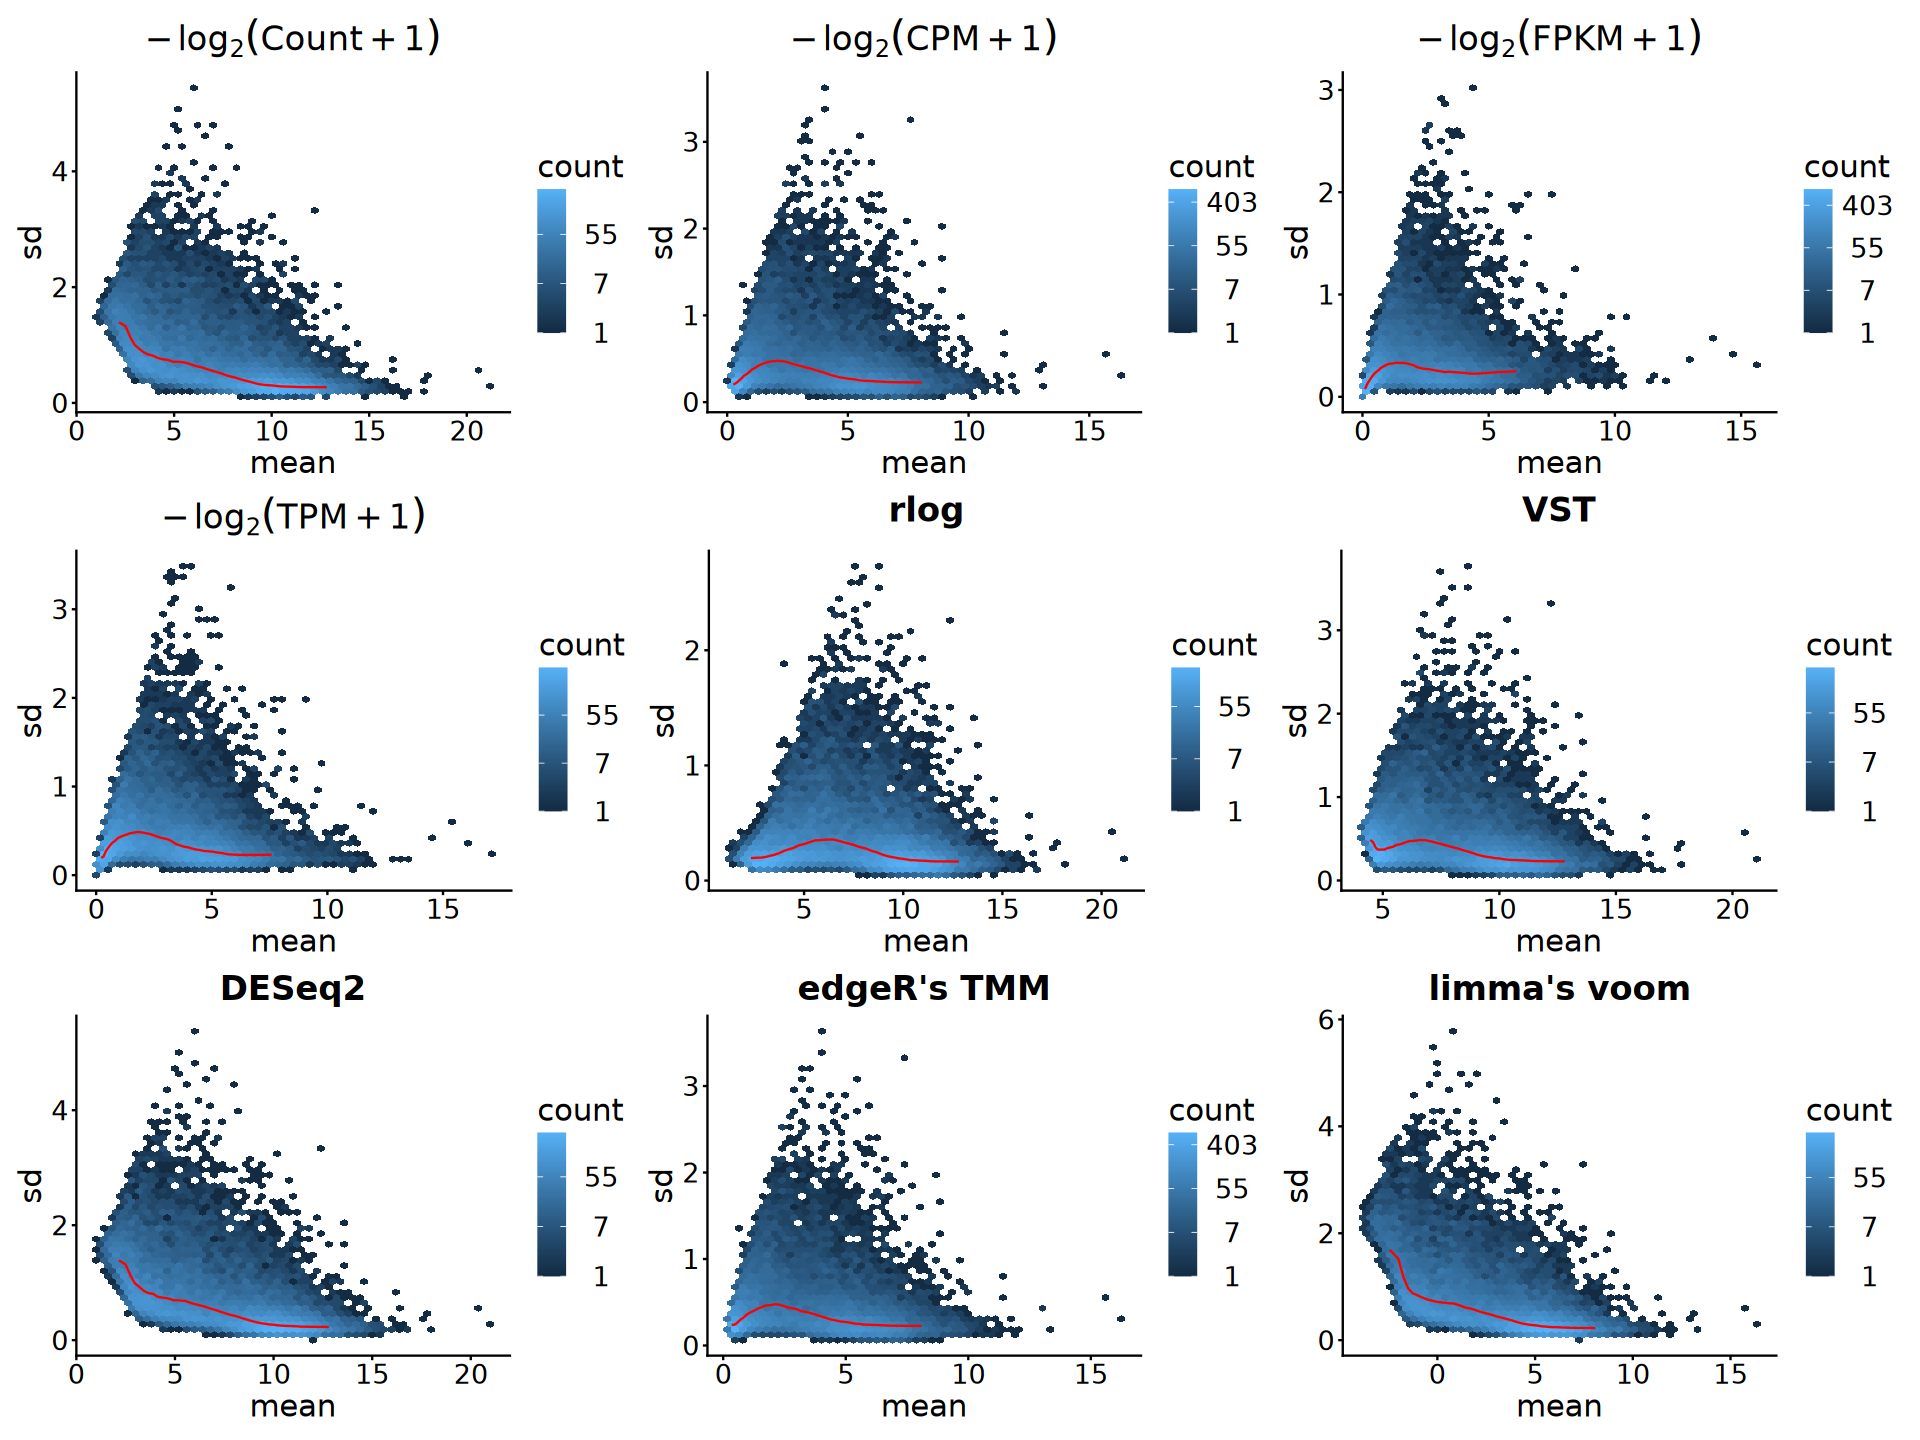

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Cell, Genotype, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

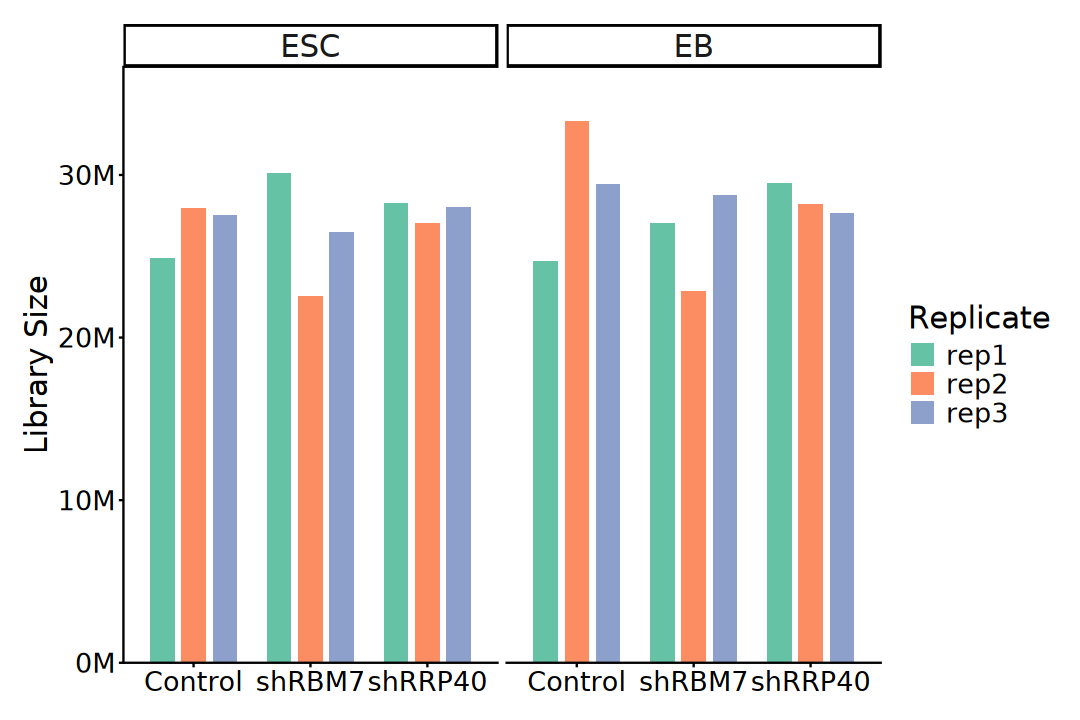

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Genotype, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ Cell, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [45]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [46]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [47]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
pca_res <- plotPCA(
    rld, intgroup = c("Genotype", "Cell"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [49]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [51]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Genotype, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

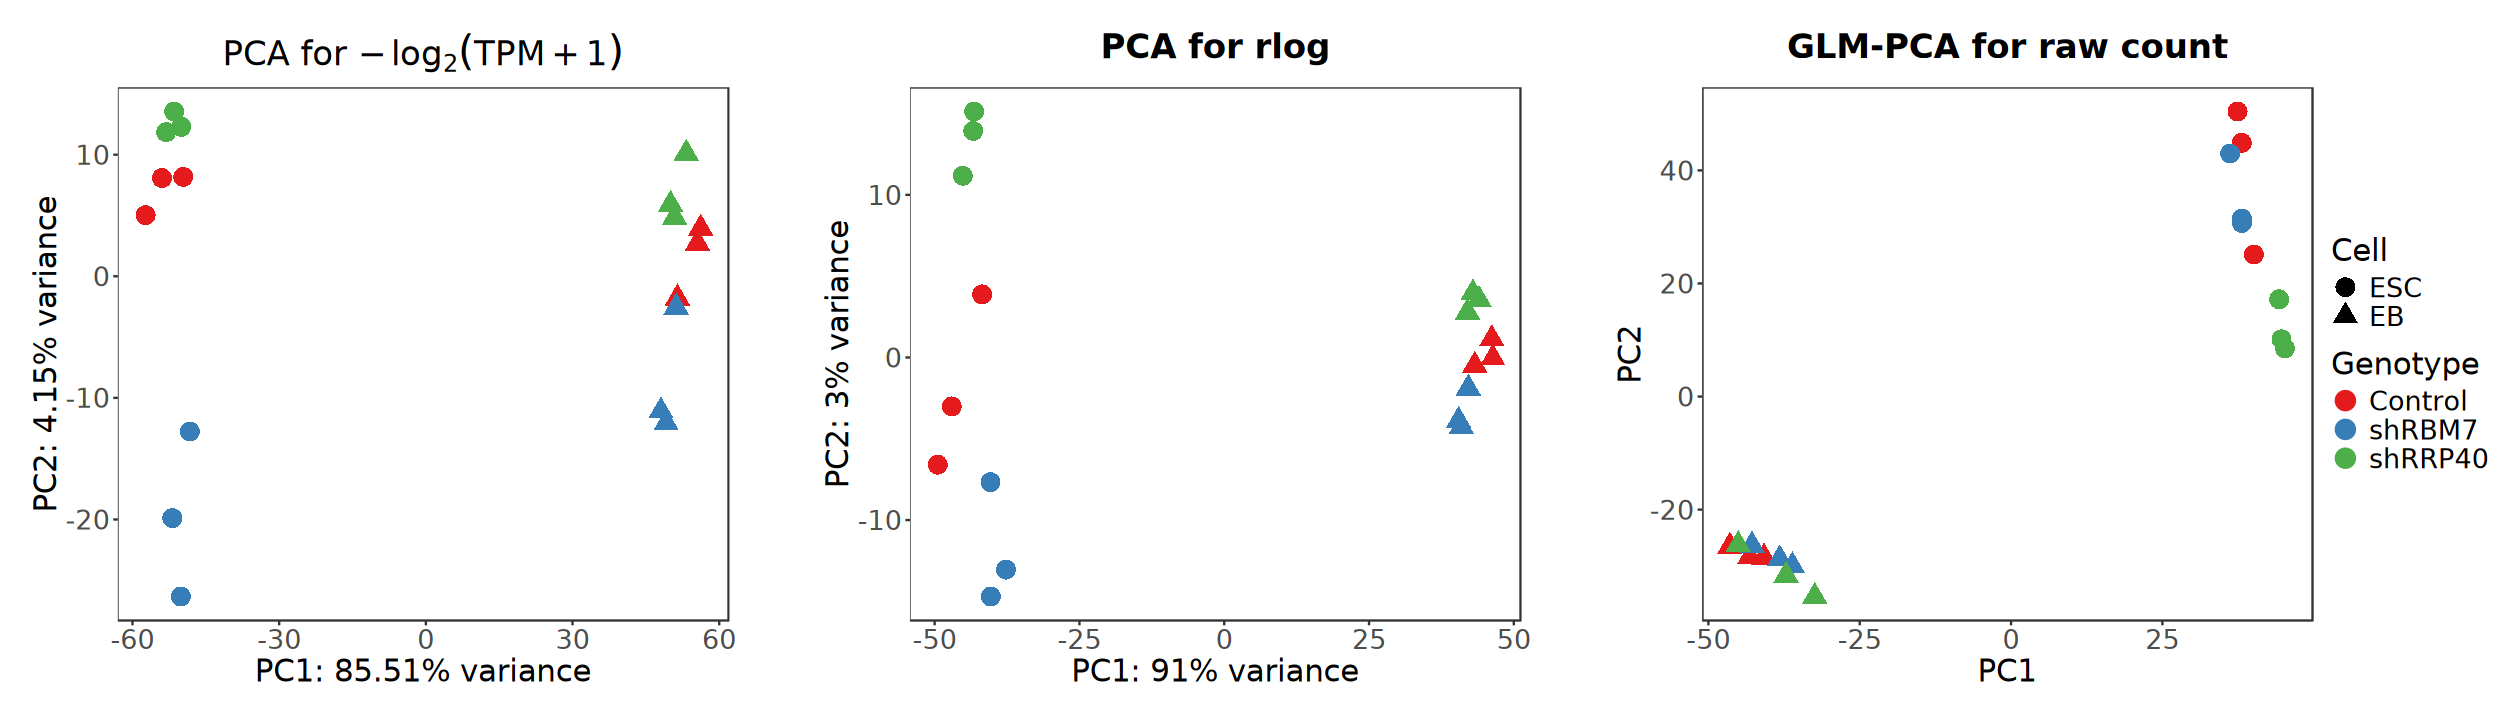

In [52]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [53]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

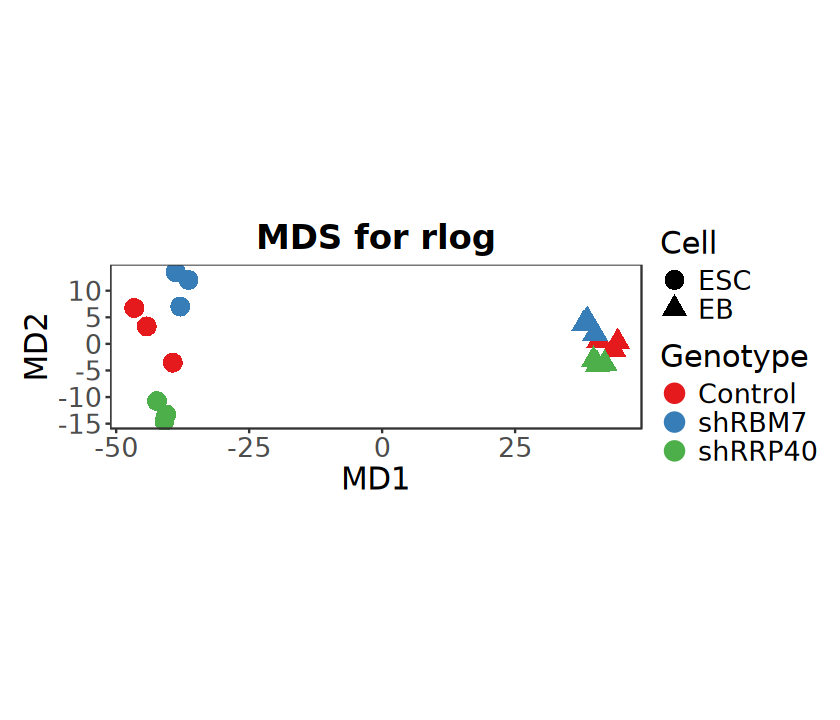

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Genotype, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [55]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

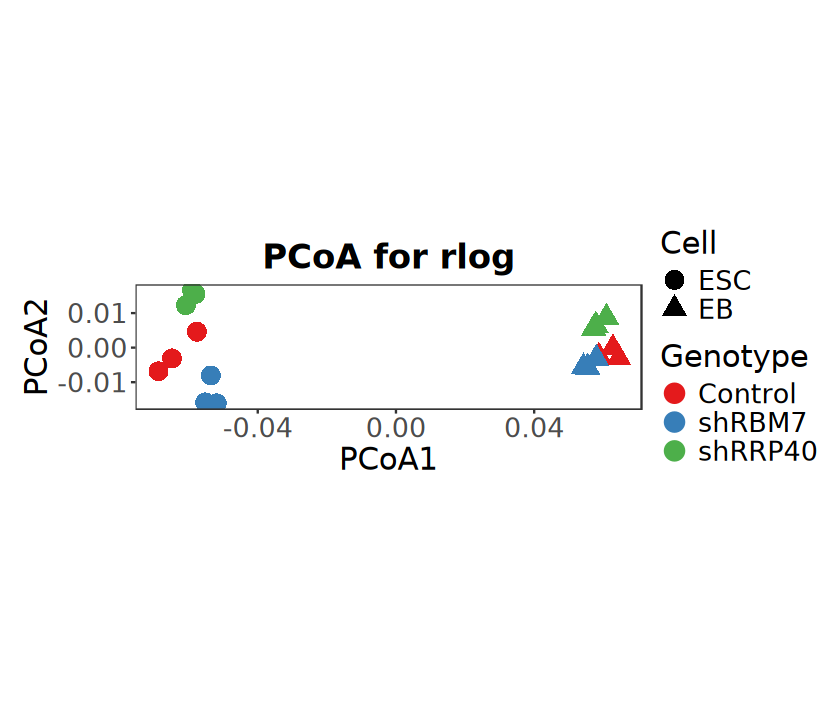

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Genotype, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [57]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Genotype, Cell)

In [58]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Genotype)),
    levels(eSet$Genotype))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
cell_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Cell)),
    levels(eSet$Cell))

anno_colors <- list(
    Cell = cell_colors,
    Group = group_colors,
    Status = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [59]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

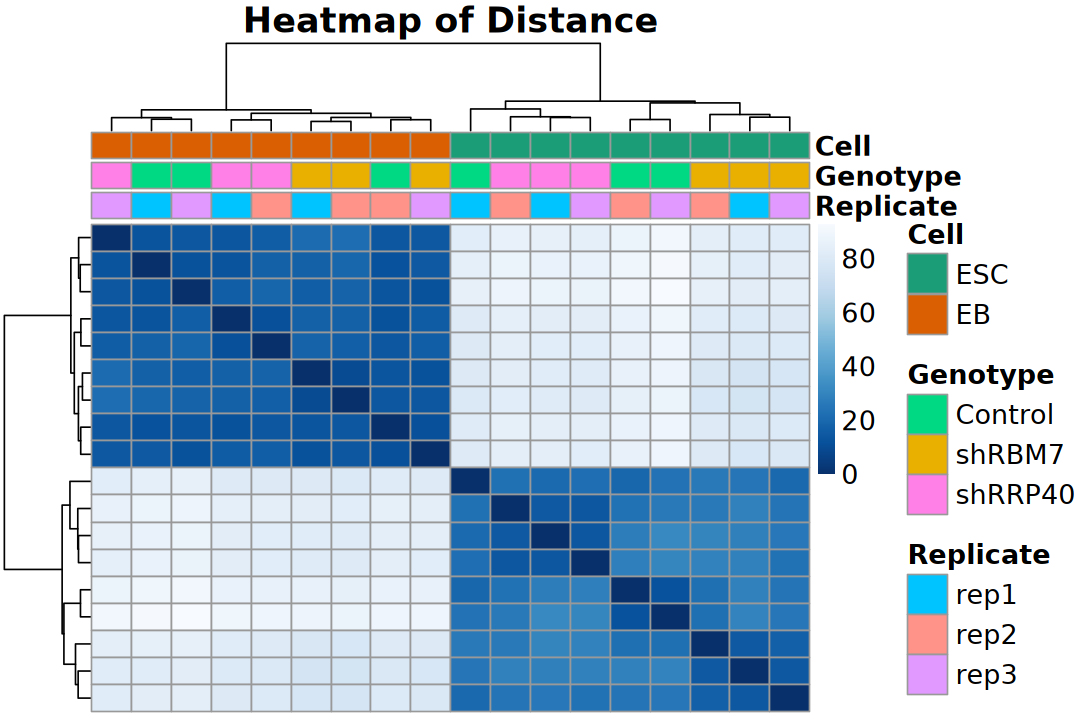

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [61]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

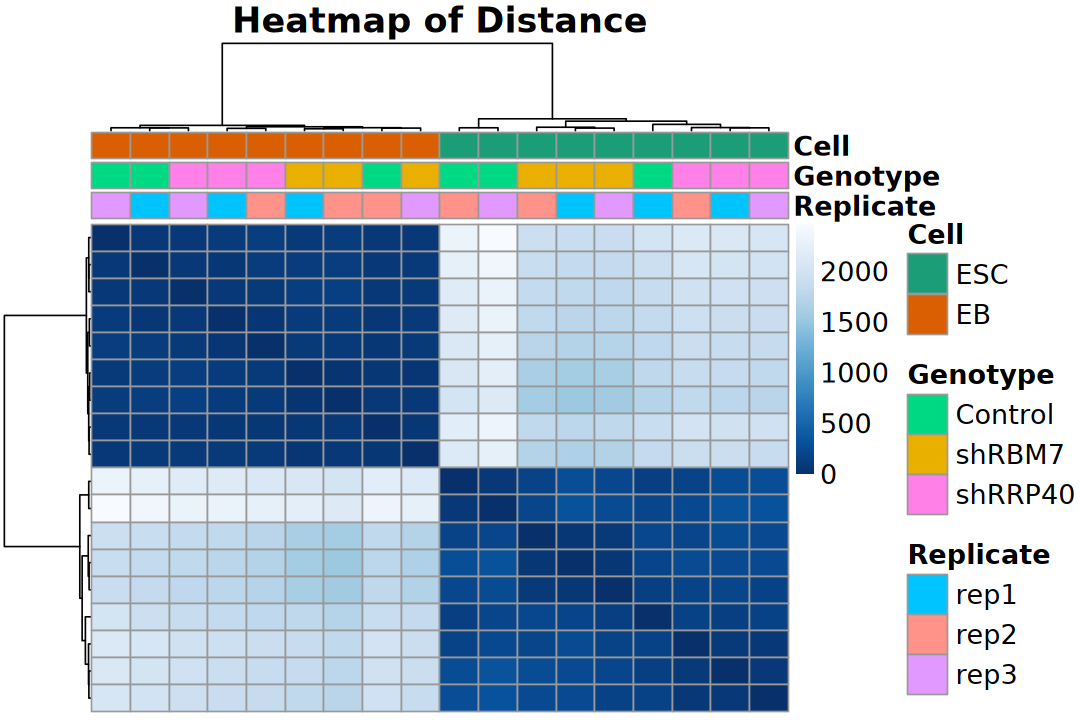

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [63]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

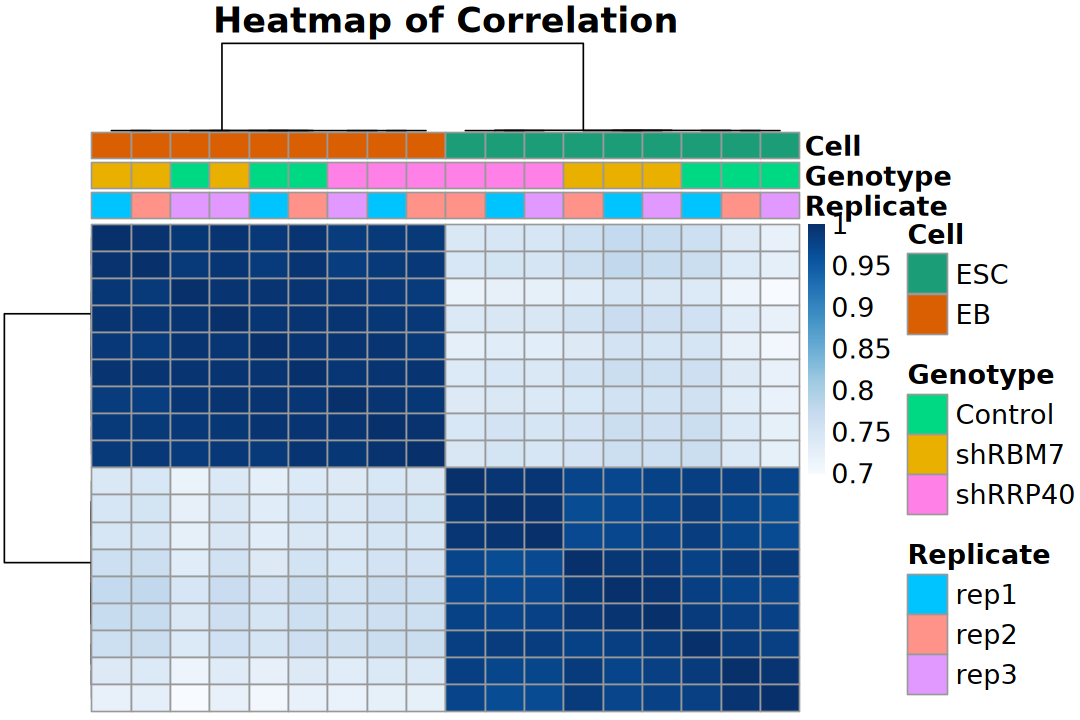

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

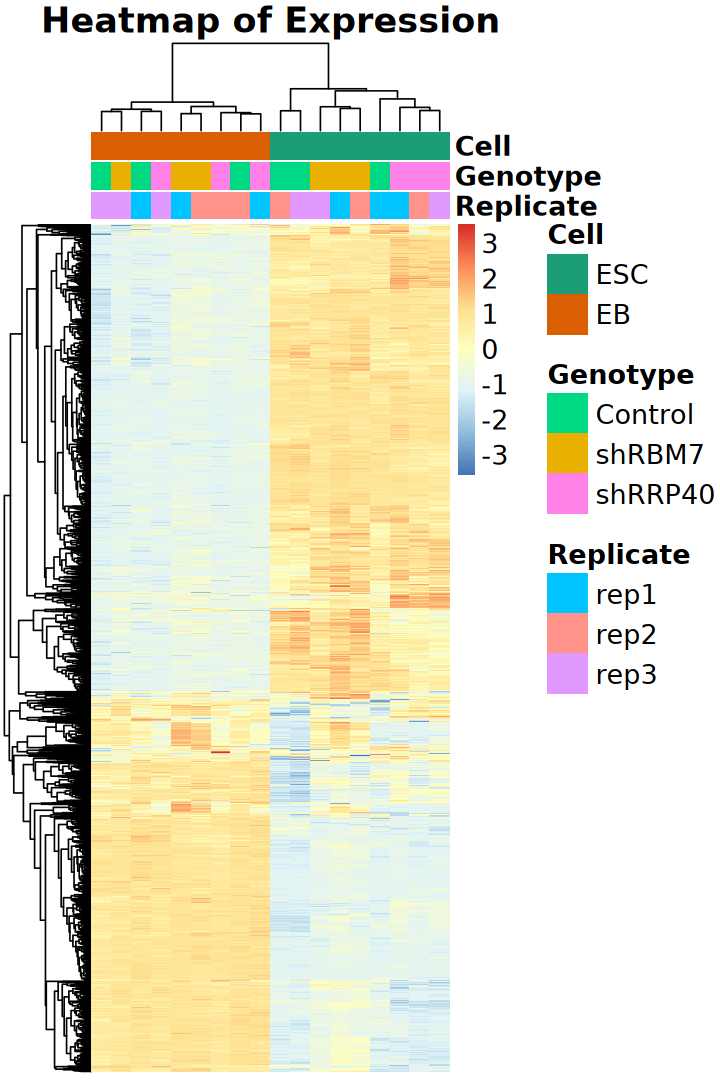

In [65]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [66]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [67]:
design(dds) <- ~ Cell + Genotype
design(dds)

~Cell + Genotype

In [68]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [69]:
resultsNames(dds)

[1] "Intercept"                   "Cell_EB_vs_ESC"             
[3] "Genotype_shRBM7_vs_Control"  "Genotype_shRRP40_vs_Control"

### a). Standard

In [72]:
# res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
res <- results(
    dds, name = "Genotype_shRBM7_vs_Control", 
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "KO", "WT"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 19970 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 1, 0.005%
LFC < -1.00 (down) : 0, 0%
outliers [1]       : 1, 0.005%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [73]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
    1     0 19969 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,87.987399,-0.377800866,0.2788153,-1.355022170,0.9871791,1,NS,Xkr4,protein_coding,6094
ENSMUSG00000103377.1,12.697010,-0.357929398,0.4776636,-0.749333665,0.9127921,1,NS,Gm37180,TEC,2819
ENSMUSG00000104017.1,8.254539,0.001840423,0.5244548,0.003509212,0.9995453,1,NS,Gm37363,TEC,2233
ENSMUSG00000103025.1,6.727039,0.063316832,0.5611266,0.112838757,0.9815184,1,NS,Gm37686,TEC,2309
ENSMUSG00000103201.1,8.251693,-0.874557588,0.5356952,-1.632565657,0.5928058,1,NS,Gm37329,TEC,2057
ENSMUSG00000103161.1,21.517644,0.269433210,0.3141239,0.857729182,0.9900101,1,NS,Gm38148,TEC,3012


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [74]:
res_lfc <- lfcShrink(dds, coef = "Genotype_shRBM7_vs_Control", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 19970 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1390, 7%
LFC < 0 (down)     : 861, 4.3%
outliers [1]       : 1, 0.005%
low counts [2]     : 0, 0%
(mean count < 2)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [75]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  470     5 19495 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,87.987399,-6.227212e-02,0.1270375,0.1754105,0.4713078,NS,Xkr4,protein_coding,6094
ENSMUSG00000103377.1,12.697010,-1.923433e-02,0.1141435,0.4536561,0.7300983,NS,Gm37180,TEC,2819
ENSMUSG00000104017.1,8.254539,9.642833e-05,0.1123425,0.9972001,0.9995025,NS,Gm37363,TEC,2233
ENSMUSG00000103025.1,6.727039,3.674054e-03,0.1129322,0.9101584,0.9678499,NS,Gm37686,TEC,2309
ENSMUSG00000103201.1,8.251693,-4.084720e-02,0.1233120,0.1025604,0.3622264,NS,Gm37329,TEC,2057
ENSMUSG00000103161.1,21.517644,3.336604e-02,0.1143205,0.3910420,0.6852758,NS,Gm38148,TEC,3012


### Evaluate DEGs

In [ ]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [ ]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [ ]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

In [ ]:
# exact test
et <- exactTest(dgel_classic, pair = c("WT", "KO"))

In [ ]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)

### b). Negative binomial GLM framework

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept
design

In [ ]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [ ]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [ ]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)

### c). Quasi-likelihood pipeline (edgeR v3)

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept

In [ ]:
dgel_nbglm <- estimateDisp(dgel, design)

In [ ]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [ ]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)

### d). Quasi-likelihood pipeline (edgeR v4)

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept

In [ ]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [ ]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)

### Evaluate DEGs

In [ ]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [ ]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-tread

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples)
design

In [ ]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)

In [ ]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_tread_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_tread_result <- topTable(efit, coef = "groupRA", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_tread_result$result)
head(limma_tread_result)

### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [ ]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [ ]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)

### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [ ]:
design <- model.matrix(~ group + Status, data = dgel$samples)

In [ ]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

In [ ]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)

### Evaluate DEGs

In [ ]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    tread = limma_tread_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    tread = limma_tread_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [ ]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [ ]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [ ]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [ ]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [ ]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [ ]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [ ]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

In [ ]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [ ]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [ ]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [ ]:
suppressPackageStartupMessages(library(UpSetR))

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 5, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 5, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [ ]:
res_lfc <- lfcShrink(dds, coef = "Group_KO_vs_WT", type = "apeglm")
summary(res_lfc)

In [ ]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)

In [ ]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [ ]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [ ]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [ ]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [ ]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [ ]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [ ]:
ctrl_samples <- colnames(dds)[dds$Group == "WT"]
treat_samples <- colnames(dds)[dds$Group == "KO"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [ ]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [ ]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [ ]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [ ]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Status)),
    levels(dds$Status))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Status = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [ ]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [ ]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [ ]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [ ]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Status)),
    levels(dds$Status))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [ ]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Status)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Status = replicate_colors))

In [ ]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [ ]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [ ]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [ ]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Status", labels = levels(dds$Status))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [ ]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [ ]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [ ]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [ ]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

In [ ]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [ ]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [ ]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [ ]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [ ]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [ ]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [ ]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)